In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_excel("PJMW_MW_Hourly (2).xlsx")

In [5]:
df.head(10)

,Datetime,PJMW_MW
0,2002-12-31 01:00:00,5077
1,2002-12-31 02:00:00,4939
2,2002-12-31 03:00:00,4885
3,2002-12-31 04:00:00,4857
4,2002-12-31 05:00:00,4930
5,2002-12-31 06:00:00,5126
6,2002-12-31 07:00:00,5493
7,2002-12-31 08:00:00,5824
8,2002-12-31 09:00:00,5962
9,2002-12-31 10:00:00,6019


In [6]:
df.shape

(143206, 2)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB


In [8]:
df.describe()

,Datetime,PJMW_MW
count,143206,143206.000000
mean,2010-06-02 03:39:50.656816128,5602.375089
min,2002-04-01 01:00:00,487.000000
25%,2006-05-02 03:15:00,4907.000000
50%,2010-06-02 04:30:00,5530.000000
75%,2014-07-03 06:45:00,6252.000000
max,2018-08-03 00:00:00,9594.000000
std,NaN,979.142872


In [9]:
df.dtypes

Datetime    datetime64[ns]
PJMW_MW              int64
dtype: object

In [10]:
df['Datetime']=pd.to_datetime(df['Datetime'])
df=df.sort_values('Datetime').reset_index(drop=True)
df.head()

,Datetime,PJMW_MW
0,2002-04-01 01:00:00,4374
1,2002-04-01 02:00:00,4306
2,2002-04-01 03:00:00,4322
3,2002-04-01 04:00:00,4359
4,2002-04-01 05:00:00,4436


In [11]:
print('start date:',df['Datetime'].min())
print('end date:',df['Datetime'].max())

start date: 2002-04-01 01:00:00
end date: 2018-08-03 00:00:00


In [12]:
df.isnull().sum()

Datetime    0
PJMW_MW     0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df['Datetime'].duplicated().sum()

np.int64(4)

In [15]:
df[df['Datetime'].duplicated(keep=False)]

,Datetime,PJMW_MW
110327,2014-11-02 02:00:00,4571
110328,2014-11-02 02:00:00,4613
119063,2015-11-01 02:00:00,3927
119064,2015-11-01 02:00:00,3832
127967,2016-11-06 02:00:00,4114
127968,2016-11-06 02:00:00,4089
136703,2017-11-05 02:00:00,3984
136704,2017-11-05 02:00:00,4042


In [16]:
time_diff=df.diff()
time_diff.head()

,Datetime,PJMW_MW
0,NaT,NaN
1,0 days 01:00:00,-68.0
2,0 days 01:00:00,16.0
3,0 days 01:00:00,37.0
4,0 days 01:00:00,77.0


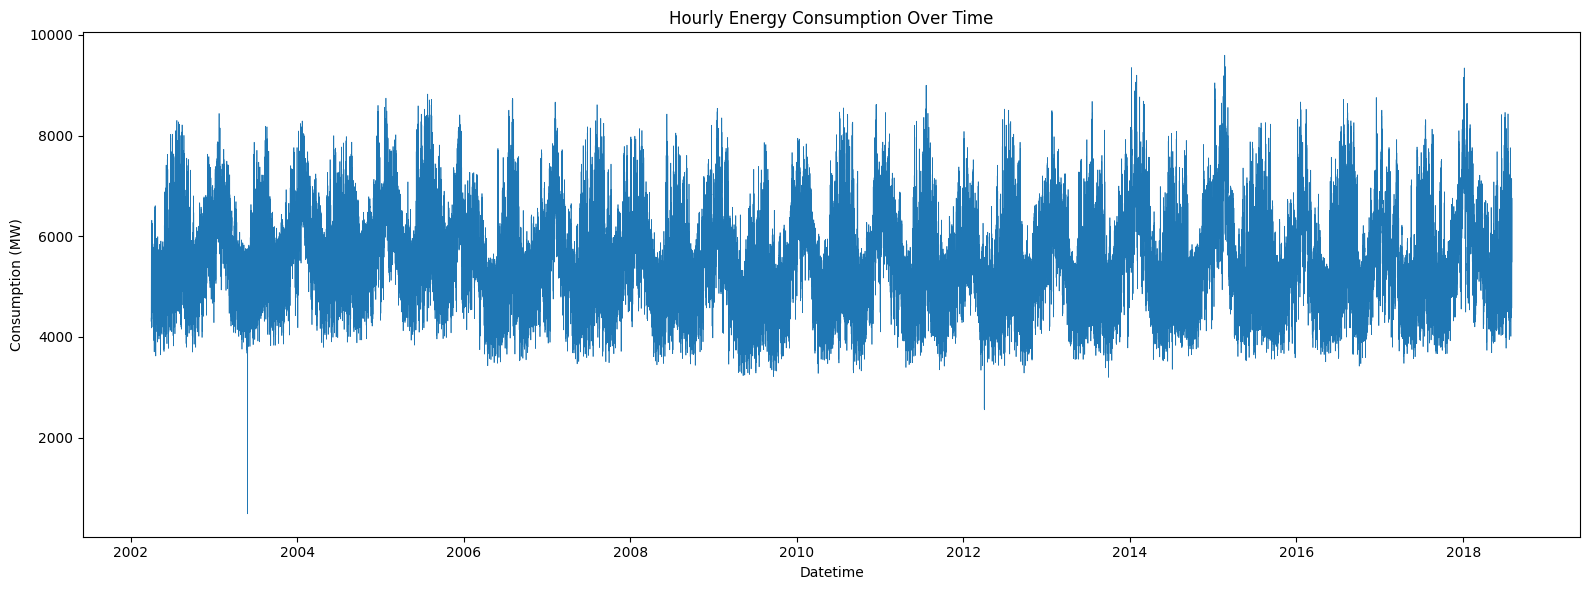

In [24]:
#hourly consumption trend
plt.figure(figsize=(16, 6))

plt.plot(
    df['Datetime'],
    df['PJMW_MW'],
    linewidth=0.5
)

plt.title('Hourly Energy Consumption Over Time')
plt.xlabel('Datetime')
plt.ylabel('Consumption (MW)')
plt.tight_layout()
plt.show()

In [35]:
daily_avg=(df.set_index('Datetime')['PJMW_MW'].resample('D').mean())
daily_avg


Datetime
2002-04-01    5271.173913
2002-04-02    5310.416667
2002-04-03    5325.916667
2002-04-04    5670.791667
2002-04-05    5686.125000
                 ...     
2018-07-30    5492.708333
2018-07-31    5660.750000
2018-08-01    5959.708333
2018-08-02    5805.041667
2018-08-03    5489.000000
Freq: D, Name: PJMW_MW, Length: 5969, dtype: float64

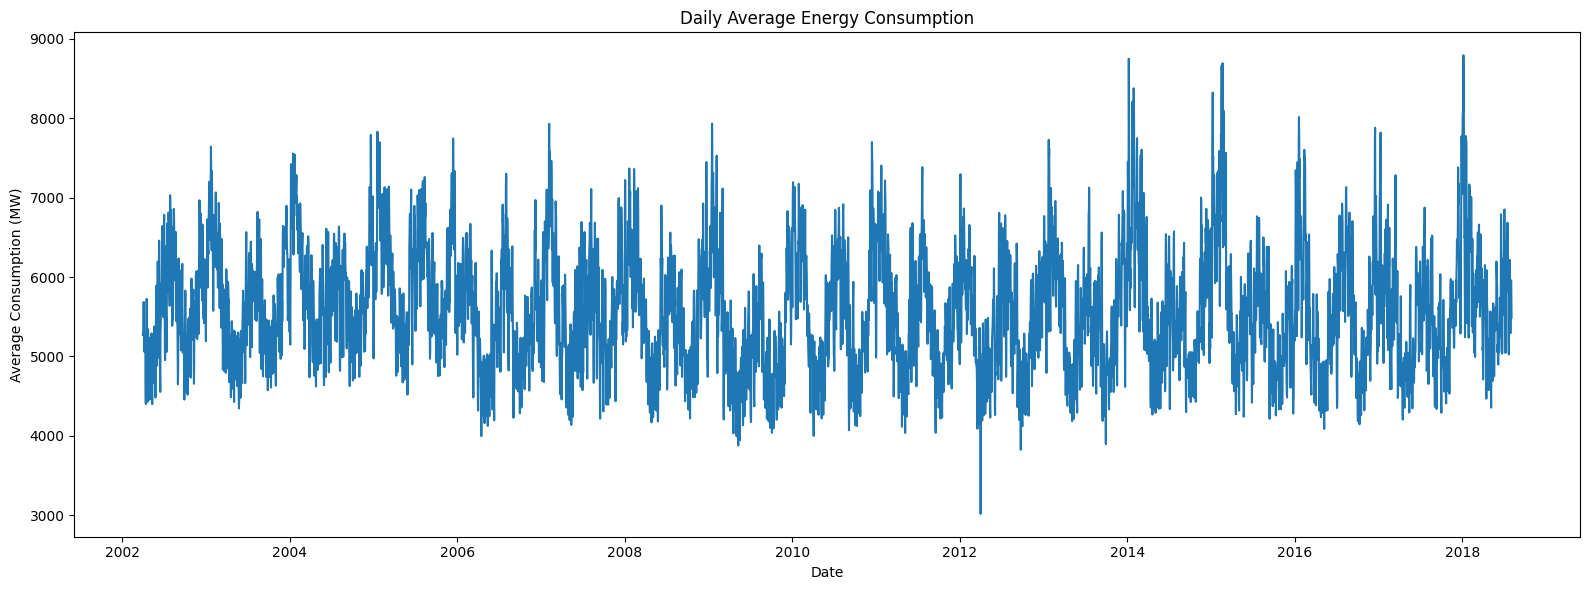

In [37]:
#plotting the daily consumption
plt.figure(figsize=(16, 6))
plt.plot(daily_avg.index, daily_avg.values)

plt.title('Daily Average Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Average Consumption (MW)')
plt.tight_layout()
plt.show()

In [38]:
monthly_avg=(df.set_index('Datetime')['PJMW_MW'].resample('ME').mean())
monthly_avg

Datetime
2002-04-30    5171.318942
2002-05-31    5085.094086
2002-06-30    5685.681944
2002-07-31    6097.877688
2002-08-31    6063.909946
                 ...     
2018-04-30    5281.277778
2018-05-31    5278.620968
2018-06-30    5559.326389
2018-07-31    5978.728495
2018-08-31    5874.346939
Freq: ME, Name: PJMW_MW, Length: 197, dtype: float64

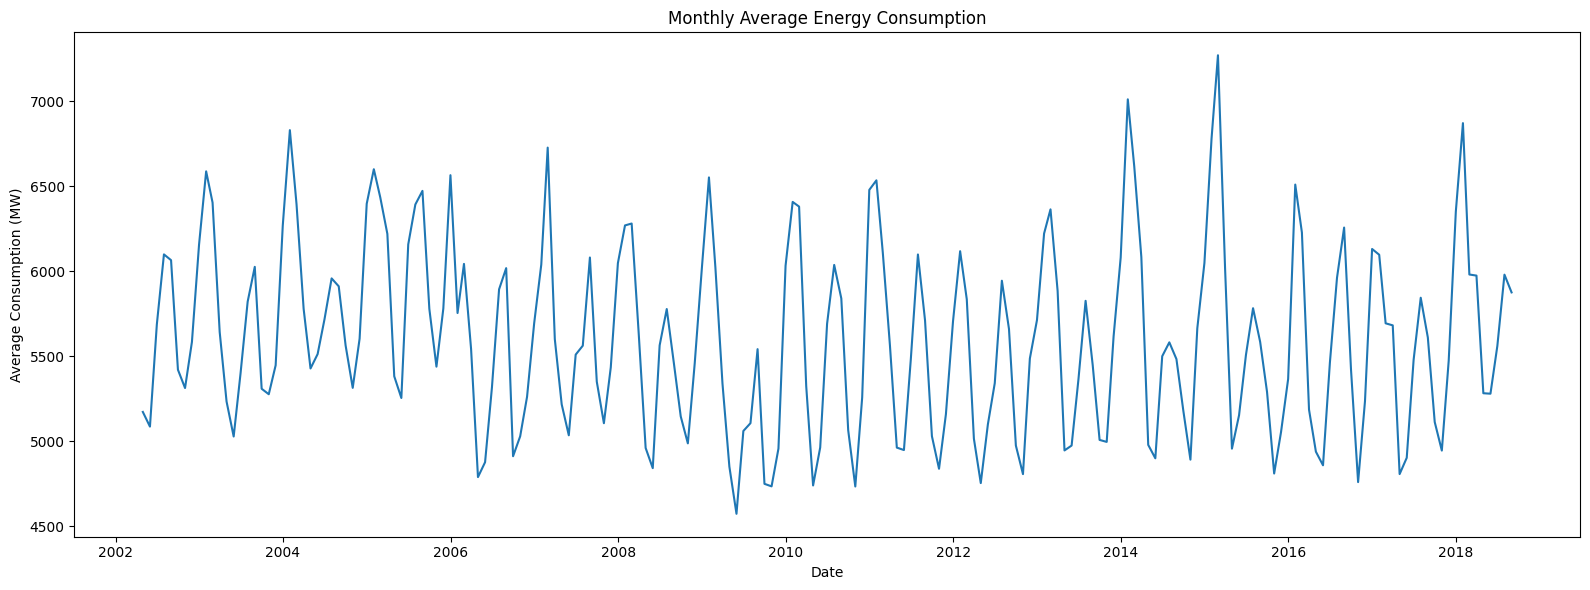

In [39]:
#plotting the daily consumption
plt.figure(figsize=(16, 6))
plt.plot(monthly_avg.index, monthly_avg.values)

plt.title('Monthly Average Energy Consumption')
plt.xlabel('Date')
plt.ylabel('Average Consumption (MW)')
plt.tight_layout()
plt.show()

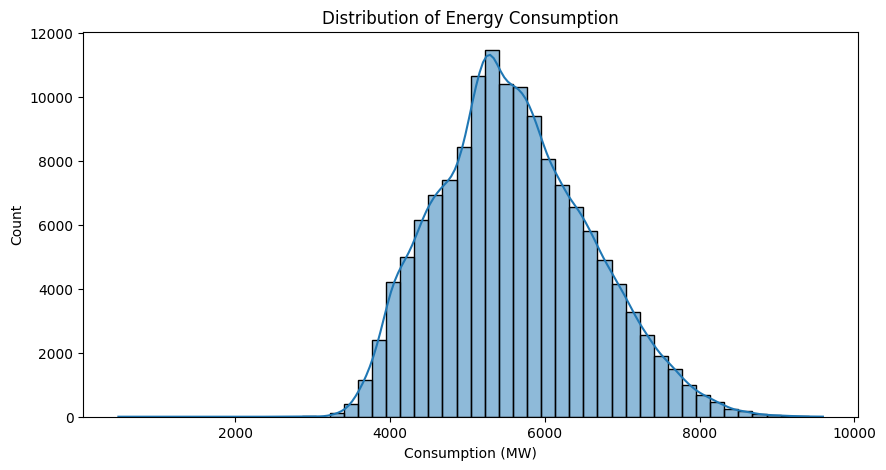

In [40]:
#Distribution of consumption
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='PJMW_MW',
    bins=50,
    kde=True
)

plt.title('Distribution of Energy Consumption')
plt.xlabel('Consumption (MW)')
plt.show()

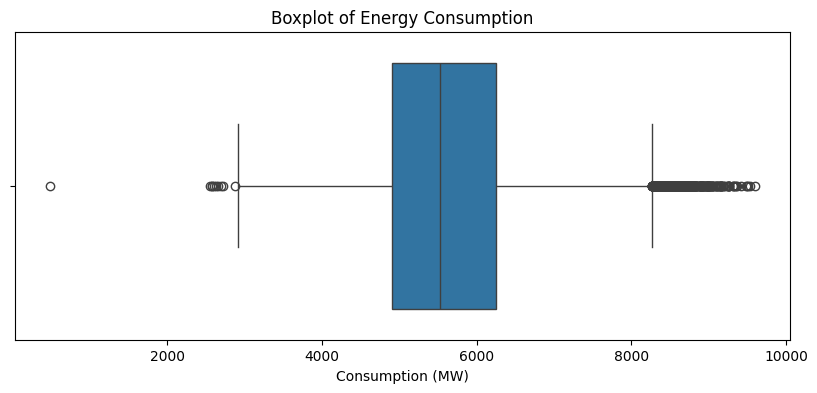

In [41]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df['PJMW_MW'])

plt.title('Boxplot of Energy Consumption')
plt.xlabel('Consumption (MW)')
plt.show()

In [54]:
df['hour']=df['Datetime'].dt.hour
df['day']=df['Datetime'].dt.day
df['day_of_week']=df['Datetime'].dt.dayofweek
df['month']=df['Datetime'].dt.month
df['year']=df['Datetime'].dt.year
df['day_of_year']=df['Datetime'].dt.dayofyear

In [56]:
df.head()

,Datetime,PJMW_MW,hour,day,day_of_week,month,year,day_of_year
0,2002-04-01 01:00:00,4374,1,1,0,4,2002,91
1,2002-04-01 02:00:00,4306,2,1,0,4,2002,91
2,2002-04-01 03:00:00,4322,3,1,0,4,2002,91
3,2002-04-01 04:00:00,4359,4,1,0,4,2002,91
4,2002-04-01 05:00:00,4436,5,1,0,4,2002,91


In [61]:
hourly_avg=df.groupby('hour')['PJMW_MW'].mean()
hourly_avg

hour
0     5230.368359
1     4940.489276
2     4779.152349
3     4697.121996
4     4672.537366
5     4734.933479
6     4958.209450
7     5323.434316
8     5571.168398
9     5708.667058
10    5818.219169
11    5904.120476
12    5947.523794
13    5959.946716
14    5970.935824
15    5953.164712
16    5957.636394
17    6031.231233
18    6158.806803
19    6199.285355
20    6183.568365
21    6152.210121
22    5982.300436
23    5618.226206
Name: PJMW_MW, dtype: float64

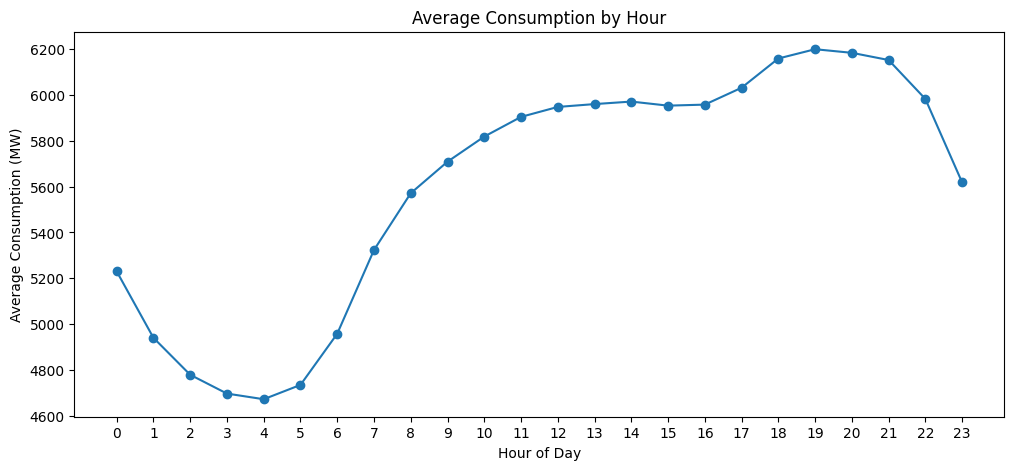

In [63]:

plt.figure(figsize=(12, 5))

plt.plot(hourly_avg.index, hourly_avg.values, marker='o')

plt.xticks(range(24))
plt.xlabel('Hour of Day')
plt.ylabel('Average Consumption (MW)')
plt.title('Average Consumption by Hour')

plt.show()

In [65]:
import numpy as np
df['day_type'] = np.where(
    df['day_of_week'] < 5,
    'Weekday',
    'Weekend'
)

In [72]:
day_type_avg = df.groupby('day_type')['PJMW_MW'].mean()

print(day_type_avg)

day_type
Weekday    5754.345669
Weekend    5221.863008
Name: PJMW_MW, dtype: float64


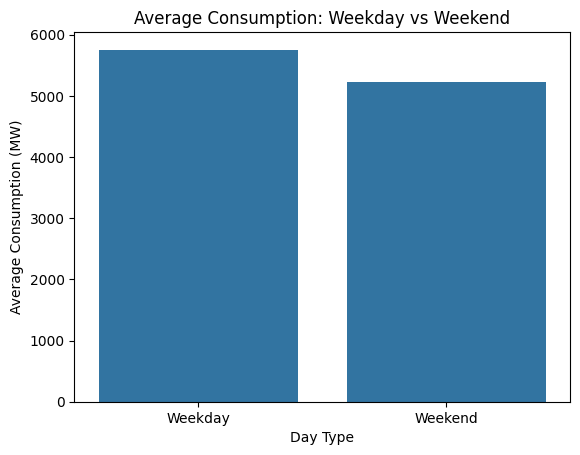

In [73]:
sns.barplot(
    data=df,
    x='day_type',
    y='PJMW_MW',
    order=['Weekday', 'Weekend'],
    errorbar=None
)

plt.title('Average Consumption: Weekday vs Weekend')
plt.xlabel('Day Type')
plt.ylabel('Average Consumption (MW)')
plt.show()

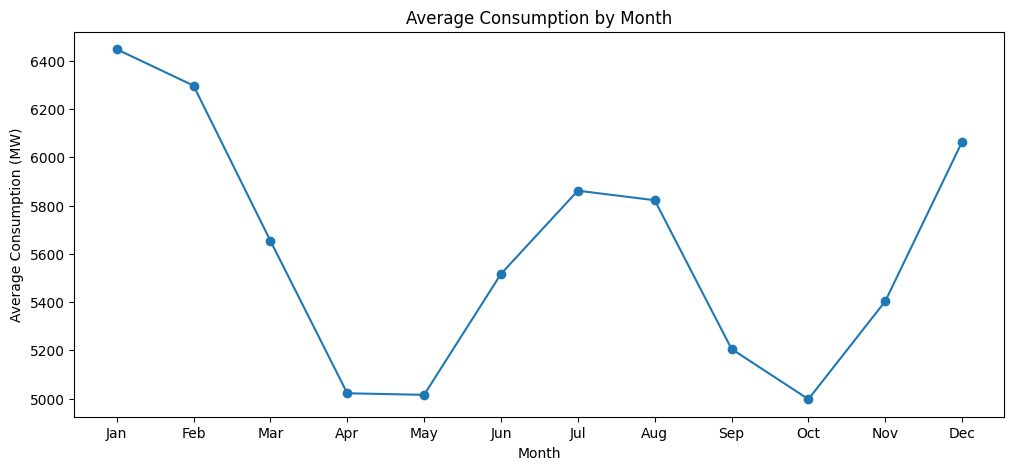

In [74]:
month_avg = df.groupby('month')['PJMW_MW'].mean()

month_names = [
    'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
]

plt.figure(figsize=(12, 5))
plt.plot(month_avg.index, month_avg.values, marker='o')

plt.xticks(range(1, 13), month_names)
plt.xlabel('Month')
plt.ylabel('Average Consumption (MW)')
plt.title('Average Consumption by Month')

plt.show()